In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import sdmetrics
print(sdmetrics.__version__)

In [ ]:
real = pd.read_csv(r'..../Train/SGA_train.csv')
real

In [ ]:
syn = pd.read_csv(r'..../SGA_smote/Synthetic.csv')
syn_df = syn.drop(columns=['Unnamed: 0'], axis=1)
syn_df

In [ ]:
# Get the column order from df1
syn_df_columns = syn_df.columns

# Reorder df2 to match df1's column order
real_reordered = real[syn_df_columns]

# print("df1:\n", sm_df)
# print("\ndf2_reordered:\n", real_reordered)
real_reordered

# Separate classes

In [ ]:
real_0 =real_reordered[real_reordered['Necrotizing Enterocolitis '] == 0]
real_1 = real_reordered[real_reordered['Necrotizing Enterocolitis '] == 1]

In [ ]:
syn_df_0 =syn_df[syn_df['Necrotizing Enterocolitis '] == 0]
syn_df_1 = syn_df[syn_df['Necrotizing Enterocolitis '] == 1]

In [ ]:
# Plot Control

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA

real_0 = real_0.copy()
syn_df_before_0 = syn_df_0.copy()

num_cols_0=real_0.select_dtypes(include=np.number).columns.tolist()
cat_cols_0 = [c for c in real_0.columns if c not in num_cols_0]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols_0),
    ("cat", OneHotEncoder(handle_unknown='ignore'), cat_cols_0)
])

# Fit on real data and transform all
real_0_emb = preprocessor.fit_transform(real_0)
syn_df_before_0_emb = preprocessor.transform(syn_df_before_0)


# Reduce to 2D (PCA)
pca = PCA(n_components=2, random_state=42)
real_0_2d = pca.fit_transform(real_0_emb)#.toarray() if hasattr(real_0_emb, "toarray") else real_0_emb)
syn_before_0_2d = pca.transform(syn_df_before_0_emb)#.toarray() if hasattr(syn_df_before_0_emb, "toarray") else syn_df_before_0_emb)


In [ ]:
# Plot NEC

real_1 = real_1.copy()
syn_df_before_1 = syn_df_1.copy()


num_cols_1=real_1.select_dtypes(include=np.number).columns.tolist()
cat_cols_1 = [c for c in real_1.columns if c not in num_cols_1]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols_1),
    ("cat", OneHotEncoder(handle_unknown='ignore'), cat_cols_1)
])

# Fit on real data and transform all
real_1_emb = preprocessor.fit_transform(real_1)
syn_df_before_1_emb = preprocessor.transform(syn_df_before_1)


# Reduce to 2D (PCA)
pca_1 = PCA(n_components=2, random_state=42)
real_1_2d = pca_1.fit_transform(real_1_emb)#.toarray() if hasattr(real_0_emb, "toarray") else real_0_emb)
syn_before_1_2d = pca_1.transform(syn_df_before_1_emb)#.toarray() if hasattr(syn_df_before_0_emb, "toarray") else syn_df_before_0_emb)

expl_var_1 = pca_1.explained_variance_ratio_ * 100
xlab_1 = (f"PC1 ({expl_var_1[0]:.1f}% variance)")
ylab_1 = (f"PC2 ({expl_var_1[1]:.1f}% variance)")

In [ ]:
plt.figure(figsize=(15,10))

# Before filtering
plt.subplot(2,2,1)
sns.kdeplot(x=real_0_2d[:,0], y=real_0_2d[:,1], fill=True, alpha=0.2, color='blue', label='Real density')
plt.scatter(syn_before_0_2d[:,0], syn_before_0_2d[:,1], s=10, alpha=0.4, c='orange', label='Synthetic')
plt.title("Control")
plt.xlabel(xlab); plt.ylabel(ylab)
plt.legend()

# Before filtering
plt.subplot(2,2,2)
sns.kdeplot(x=real_1_2d[:,0], y=real_1_2d[:,1], fill=True, alpha=0.2, color='blue', label='Real density')
plt.scatter(syn_before_1_2d[:,0], syn_before_1_2d[:,1], s=10, alpha=0.4, c='green', label='Synthetic')
plt.title("NEC")
#plt.xlabel("PC1"); plt.ylabel("Synthetic before")
plt.xlabel(xlab_1); plt.ylabel(ylab_1)
plt.legend()

#plt.suptitle(f"Density Overlay of Real and Synthetic Data. PC1+PC2 explained {(expl_var_1[0]+expl_var_1[1]):.1f}% variance", fontsize=14)
plt.suptitle(f"Density Overlay of Real and Synthetic Data", fontsize=14)
plt.tight_layout()

#plt.savefig("..../PCA_real_synthetic_overlay.png", dpi=300)
 
plt.show()

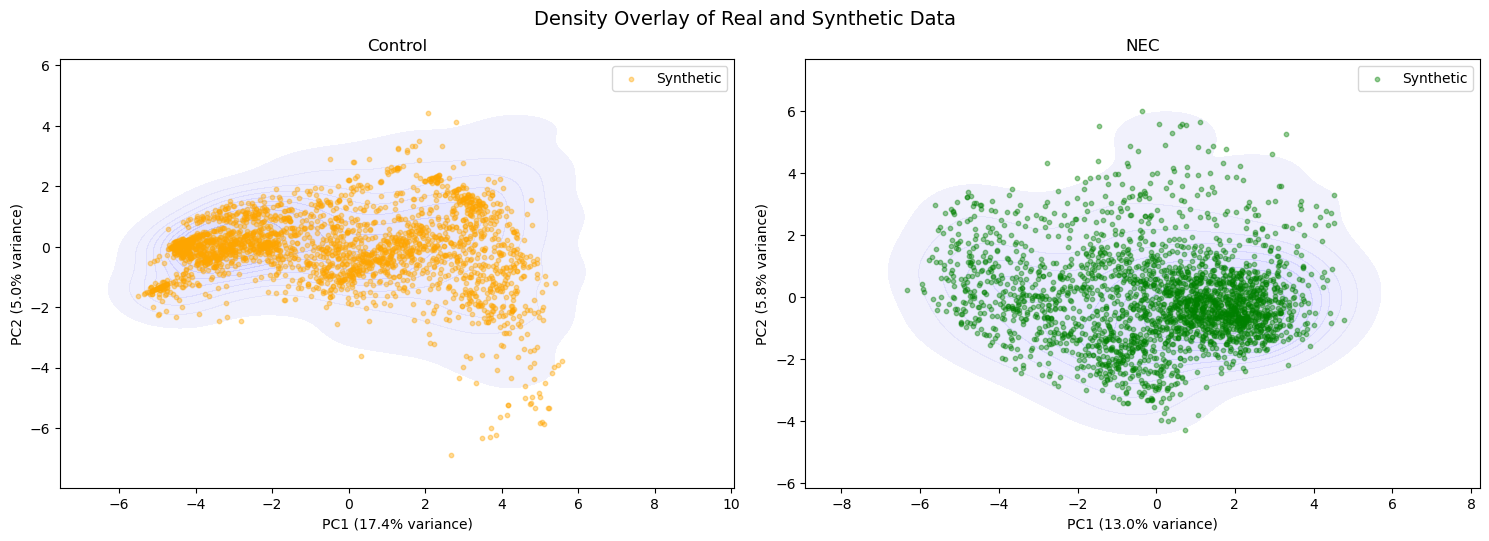

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

REAL_BLUE   = "#163a5f"   # deep blue (real)
SYNTH_GREEN = "#0b5f6a" #teal,  #"#0f5d3f"   # dark, deep green (synthetic)

# Explained variance (given)
pc1_ctrl, pc2_ctrl = 17.4, 5.0
pc1_nec,  pc2_nec  = 13.0, 5.8

xlab_ctrl = f"PC1 ({pc1_ctrl:.1f}% variance explained)"
ylab_ctrl = f"PC2 ({pc2_ctrl:.1f}% variance explained)"
xlab_nec  = f"PC1 ({pc1_nec:.1f}% variance explained)"
ylab_nec  = f"PC2 ({pc2_nec:.1f}% variance explained)"

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=False, sharey=False)

def style_axes(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(True, alpha=0.18)
    ax.set_axisbelow(True)

# ---------- Panel A: Control ----------
ax = axes[0]
sns.kdeplot(
    x=real_0_2d[:, 0], y=real_0_2d[:, 1],
    fill=True, alpha=0.28, color=REAL_BLUE,
    ax=ax, thresh=0.04, levels=10, bw_adjust=1.0
)

syn_scatter_ctrl = ax.scatter(
    syn_before_0_2d[:, 0], syn_before_0_2d[:, 1],
    s=12, alpha=0.55, c=SYNTH_GREEN,
    linewidths=0, rasterized=True, label="Synthetic (points)"
)

ax.set_title("Control")
ax.set_xlabel(xlab_ctrl)
ax.set_ylabel(ylab_ctrl)
style_axes(ax)

real_density_patch = Patch(facecolor=REAL_BLUE, alpha=0.18, label="Real (density)")
ax.legend(handles=[real_density_patch, syn_scatter_ctrl], frameon=False)

# ---------- Panel B: NEC ----------
ax = axes[1]
sns.kdeplot(
    x=real_1_2d[:, 0], y=real_1_2d[:, 1],
    fill=True, alpha=0.28, color=REAL_BLUE,
    ax=ax, thresh=0.04, levels=10, bw_adjust=1.0
)

syn_scatter_nec = ax.scatter(
    syn_before_1_2d[:, 0], syn_before_1_2d[:, 1],
    s=12, alpha=0.55, c="#5b3c88",
    linewidths=0, rasterized=True, label="Synthetic (points)"
)

ax.set_title("NEC")
ax.set_xlabel(xlab_nec)
ax.set_ylabel(ylab_nec)
style_axes(ax)

real_density_patch = Patch(facecolor=REAL_BLUE, alpha=0.18, label="Real (density)")
ax.legend(handles=[real_density_patch, syn_scatter_nec], frameon=False)

fig.suptitle("Principal component analysis of real and synthetic clinical data", fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# Optional exports:
#fig.savefig("PCA_real_synthetic_overlay_consistent.png", dpi=600, bbox_inches="tight")
# fig.savefig("PCA_real_synthetic_overlay_consistent.pdf", dpi=300, bbox_inches="tight")

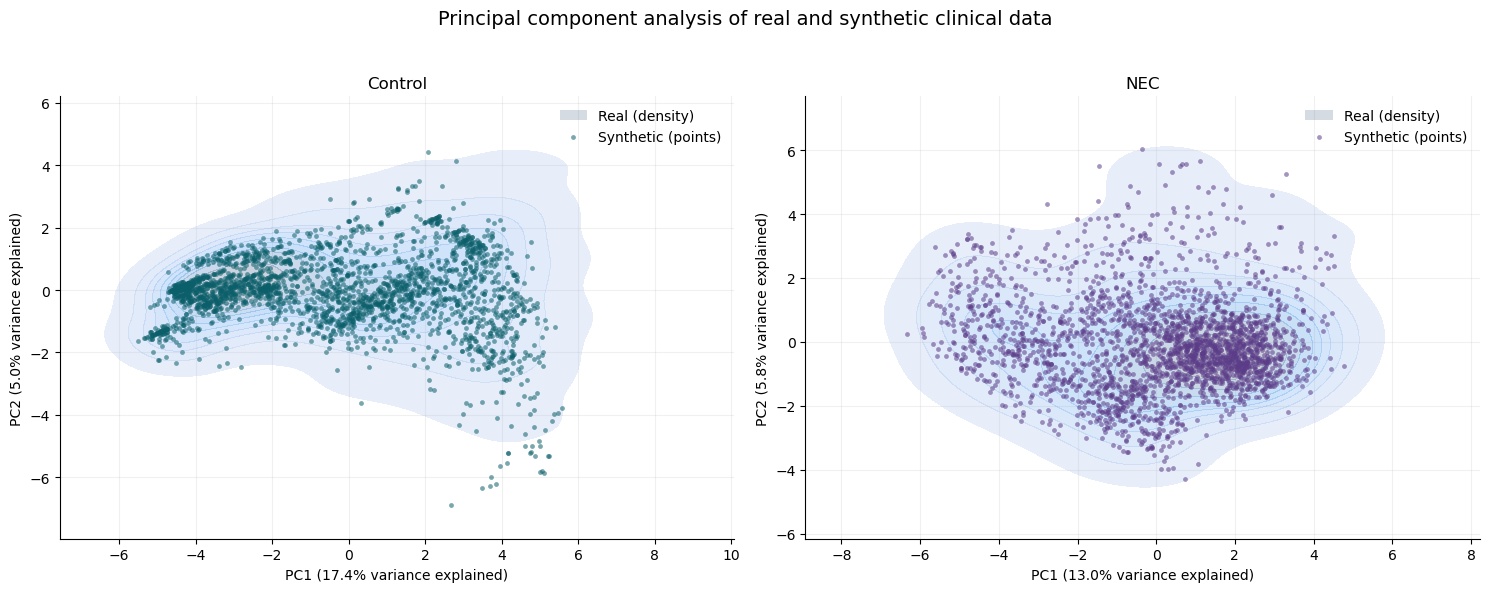